# Notebook 04 — Clusterização com K-Means: os dados se separam sozinhos? (coleta intercalada NOVOS_2.0)

**O que buscamos aqui:** descobrir o quanto as condições do ventilador se separam **sem que o algoritmo saiba os rótulos**. Se os grupos aparecem sozinhos, a diferença entre as condições é forte, e um classificador treinado com rótulos (Notebook 05) tende a funcionar ainda melhor. Se não aparecem, entendemos **por quê** antes de treinar qualquer modelo.

**A pergunta principal desta versão: o K-Means "enxerga" o calço?** O Notebook 02 mostrou que o calço fica dentro da variação do normal ao longo da sessão, mas diferente dos seus dois vizinhos, e que a Vel 3 é onde ele mais aparece. Aqui fazemos o teste sem rótulos.

**O cuidado que muda tudo nesta coleta:** os 5 lotes de normal **já são diferentes entre si** (o motor esquenta de lote para lote). Então "o K-Means separou o calço do normal" só significa algo se ele separar o calço **mais do que separa um lote normal de outro**. Por isso todo resultado de anomalia vem acompanhado de um **placebo**: o mesmo experimento com um lote normal no lugar da anomalia.

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configuração | Conjuntos de features, log e scaler |
| 2 | Carregar as bases, calcular as 109 features e montar o gabarito | A mesma tabela dos Notebooks 02 e 03 |
| 3 | Log e scaler (global e local "b") | Colocar as features na mesma escala sem apagar o que importa |
| 4 | Como medir | Matriz de confusão, recall, falso alarme, acurácia balanceada e ARI |
| 5 | K=3 nos normais e em cada falha | O K-Means acha as 3 velocidades? |
| 6 | K=5 só nos normais | O K-Means separa os **lotes** de normal (momento da sessão)? |
| 7 | K=2 em cada velocidade: normal × cada anomalia | O teste de detecção, contra os 5 normais e contra os vizinhos |
| 8 | **O teste do calço** | O calço se separa mais do que um lote normal se separa dos outros (placebo)? |
| 9 | K=5 em cada velocidade e K=15 | Todas as condições ao mesmo tempo |
| Resumo | Tabela final e decisões | O que levar para o Notebook 05 |

## O que é o K-Means (em uma linha)

Ele recebe as janelas como pontos num espaço de 109 dimensões (uma por feature), escolhe **K centros** e coloca cada janela no grupo do centro mais próximo, ajustando os centros até estabilizar. **Ele mede distância**, por isso a escala das features (Passo 3) muda tudo.

## Ressalvas que valem para todo o notebook

* **Os rótulos ficam guardados à parte** e só entram no fim de cada experimento, para conferir o que o K-Means encontrou. As exceções são o scaler local "b" (que precisa saber a velocidade e quem é normal) e a escolha de **quais janelas** entram em cada experimento.
* **Uma gravação por anomalia e velocidade:** quando o K-Means separa uma anomalia, parte da diferença pode ser **da gravação**. O placebo mede o tamanho desse efeito com os lotes de normal.
* **Poucas janelas:** cada gravação tem de 33 a 43 janelas, então uma diferença de 2 ou 3 janelas muda o recall em cerca de 5 a 8 pontos.
* **Não há divisão treino/teste aqui.** O K-Means não aprende rótulos, mas os scalers são ajustados nos próprios dados analisados. Isso serve para a **viabilidade**; no Notebook 05 os scalers são ajustados **só no treino**.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte. Precisa de `scikit-learn` instalado.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import kurtosis
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})
pd.set_option("display.width", 200)

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos notebooks anteriores)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS\NOVOS_2.0")
BUSCAR_EM_SUBPASTAS = True
DESCARTAR_INICIO_S = 5
DESCARTAR_FIM_S = 5

# ----------------------------------------------------------------------
# ORDEM DA SESSÃO (a mesma dos Notebooks 01 a 03)
# ATENÇÃO: a ordem entre fita_1g e fita_05g NÃO foi anotada; aqui está assumida (1 g antes de 0,5 g).
# ----------------------------------------------------------------------
ORDEM_SESSAO = [
    "ventilador_normal", "calco", "ventilador_normal", "fita_1g", "ventilador_normal",
    "fita_05g", "ventilador_normal", "papel", "ventilador_normal",
]
CONDICAO_NORMAL = "ventilador_normal"
NOME_NORMAL = "normal"            # rótulo usado nas matrizes para o normal
CONDICAO_FOCO = "calco"           # a anomalia do teste principal (Passo 8)

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6

# ----------------------------------------------------------------------
# LOG (Passo 3; decisão do Notebook 03)
# ----------------------------------------------------------------------
APLICAR_LOG = True
COLUNAS_SEM_LOG = ["kurt_x", "kurt_y", "kurt_z"]   # a curtose pode ser negativa: não aceita log

# ----------------------------------------------------------------------
# K-MEANS
# ----------------------------------------------------------------------
N_INIT = 20                       # o K-Means recomeça 20 vezes de pontos diferentes e fica com o melhor resultado
SEMENTE = 42                      # fixa os sorteios para o resultado ser sempre igual
CONJUNTO_PRINCIPAL = "todas"      # conjunto de features das figuras (os outros aparecem nas tabelas)

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_VELOCIDADE = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
COR_ANOMALIA = "crimson"
COR_PLACEBO = "dimgray"

## Passo 2 — Carregar as bases, calcular as 109 features e montar o gabarito

**O que buscamos:** a mesma tabela de features dos Notebooks 02 e 03. **O código é o mesmo**, para garantir que as features sejam idênticas. Cada janela leva também o seu **bloco da sessão** (N1 a N5 para os normais; o nome da anomalia para as outras).

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)(?:_lote_(?P<lote>\d+))?$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome em condição, velocidade e lote ('ventilador_normal_vel_1_lote_3' -> ('ventilador_normal', 1, 3))."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N> ou <condicao>_vel_<N>_lote_<K>.")
    return encontrado["condicao"], int(encontrado["velocidade"]), int(encontrado["lote"] or 0)


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo)."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade, lote = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({"base": nome, "condicao": condicao, "velocidade": velocidade, "lote": lote})
    return bases, pd.DataFrame(linhas).set_index("base")


def aparar_bases(bases, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    return {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}


def adicionar_posicao_na_sessao(catalogo, ordem_sessao=ORDEM_SESSAO, condicao_normal=CONDICAO_NORMAL):
    """Acrescenta posicao_sessao e bloco (N1..N5 ou a anomalia) e ordena o catálogo pela sessão."""
    catalogo = catalogo.copy()
    posicao, lote_atual = {}, 0
    for i, condicao in enumerate(ordem_sessao, start=1):
        if condicao == condicao_normal:
            lote_atual += 1
            posicao[(condicao, lote_atual)] = i
        else:
            posicao[(condicao, 0)] = i
    sem_posicao = sorted(set(zip(catalogo["condicao"], catalogo["lote"])) - set(posicao))
    if sem_posicao:
        raise ValueError(f"Estas condições/lotes não estão em ORDEM_SESSAO: {sem_posicao}. Ajuste o Passo 1.")
    catalogo["posicao_sessao"] = [posicao[(c, l)] for c, l in zip(catalogo["condicao"], catalogo["lote"])]
    eh_normal = catalogo["condicao"] == condicao_normal
    catalogo["bloco"] = np.where(eh_normal, "N" + catalogo["lote"].astype(str), catalogo["condicao"])
    return catalogo.sort_values(["posicao_sessao", "velocidade"])

In [4]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def calcular_features_de_uma_base(df, janela_s=JANELA_S):
    """As 109 features de cada janela de uma base (tempo, FFT por faixa, rotação e harmônicas)."""
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    janelas = df[EIXOS].to_numpy()[: n_janelas * tamanho].reshape(n_janelas, tamanho, len(EIXOS))
    janelas = janelas - janelas.mean(axis=1, keepdims=True)
    colunas = {}
    std, curtose, pico = janelas.std(axis=1, ddof=1), kurtosis(janelas, axis=1, fisher=True), np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"], colunas[f"kurt_{eixo}"], colunas[f"pico_{eixo}"] = std[:, k], curtose[:, k], pico[:, k]
    magnitude = np.abs(np.fft.rfft(janelas * np.hanning(tamanho)[None, :, None], axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)
    for inicio, fim in faixas_de_frequencia():
        maximo = magnitude[:, (frequencias >= inicio) & (frequencias < fim), :].max(axis=1)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo[:, k]
    # rotação 1X em duas passadas e amplitudes harmônicas (as mesmas do Notebook 02)
    soma = magnitude.sum(axis=2)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    tipica = np.median(frequencias[na_faixa][soma[:, na_faixa].argmax(axis=1)])
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    f1x = frequencias[perto][soma[:, perto].argmax(axis=1)]
    for k in range(1, N_HARMONICAS + 1):
        perto_k = np.abs(frequencias[None, :] - (k * f1x)[:, None]) <= TOLERANCIA_HARMONICA_HZ
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto_k, magnitude[:, :, j], 0.0).max(axis=1)
    colunas["f1x_hz"] = f1x
    return pd.DataFrame(colunas)


def calcular_todas_as_features(bases, catalogo):
    """Junta as features de todas as bases numa tabela, com base, bloco, condicao, velocidade e janela."""
    tabelas = []
    for nome in catalogo.index:
        tabela = calcular_features_de_uma_base(bases[nome])
        tabela.insert(0, "janela", np.arange(len(tabela)))
        for coluna in ("velocidade", "condicao", "bloco"):
            tabela.insert(0, coluna, catalogo.loc[nome, coluna])
        tabela.insert(0, "base", nome)
        tabelas.append(tabela)
    return pd.concat(tabelas, ignore_index=True)

In [5]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases = aparar_bases(bases)
catalogo = adicionar_posicao_na_sessao(catalogo)
features = calcular_todas_as_features(bases, catalogo)

velocidades = sorted(features["velocidade"].unique())
ORDEM_BLOCOS = catalogo.drop_duplicates("bloco")["bloco"].tolist()
BLOCOS_NORMAIS = [b for b in ORDEM_BLOCOS if b.startswith("N") and b[1:].isdigit()]
ANOMALIAS = [b for b in ORDEM_BLOCOS if b not in BLOCOS_NORMAIS]

COLUNAS_TEMPO = [f"{t}_{e}" for t in ("std", "kurt", "pico") for e in EIXOS]
COLUNAS_FFT = [f"fft_{i:03d}_{f:03d}Hz_{e}" for e in EIXOS for i, f in faixas_de_frequencia()]
COLUNAS_ROTACAO = [f"amp_{k}x_{e}" for k in range(1, N_HARMONICAS + 1) for e in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO
CONJUNTOS = {
    "tempo": COLUNAS_TEMPO,
    "FFT": COLUNAS_FFT,
    "rotação": COLUNAS_ROTACAO,
    "todas": COLUNAS_TODAS,
    "todas sem f1x_hz": [c for c in COLUNAS_TODAS if c != "f1x_hz"],
}

print(f"{len(features)} janelas, {len(COLUNAS_TODAS)} features. Blocos na ordem da sessão: {ORDEM_BLOCOS}")
print({nome: len(colunas) for nome, colunas in CONJUNTOS.items()})
display(features.groupby(["bloco", "velocidade"]).size().unstack().reindex(ORDEM_BLOCOS).rename_axis(columns="Vel"))

1000 janelas, 109 features. Blocos na ordem da sessão: ['N1', 'calco', 'N2', 'fita_1g', 'N3', 'fita_05g', 'N4', 'papel', 'N5']
{'tempo': 9, 'FFT': 90, 'rotação': 10, 'todas': 109, 'todas sem f1x_hz': 108}


Vel,1,2,3
bloco,,,
N1,34,35,36
calco,35,37,43
N2,38,36,35
fita_1g,33,35,35
N3,37,36,38
fita_05g,38,38,37
N4,38,37,37
papel,38,38,38
N5,38,38,42


### 2.1 — O gabarito, guardado à parte

**O que buscamos:** separar a **matriz de features** (o que o K-Means vê) do **gabarito** (o que só usamos para conferir). O gabarito tem, para cada janela: a `velocidade`, o `bloco` (N1 a N5 ou a anomalia), a `condicao` (`normal` para os 5 lotes, ou o nome da anomalia) e a `classe` (condição + velocidade, por exemplo `calco V3`).

**Por que existe o conjunto "todas sem f1x_hz":** o Notebook 02 mostrou que a rotação mistura duas coisas, o freio que as anomalias causam na Vel 1 e o aquecimento entre os lotes. Rodar sem ela mostra o que o K-Means enxerga **só na vibração**.

In [6]:
def montar_gabarito(features, blocos_normais):
    """Tabela com os rótulos de cada janela. Não entra em nenhum K-Means, só na avaliação."""
    eh_normal = features["bloco"].isin(blocos_normais)
    condicao = np.where(eh_normal, NOME_NORMAL, features["bloco"])
    return pd.DataFrame({
        "base": features["base"], "janela": features["janela"], "velocidade": features["velocidade"],
        "bloco": features["bloco"], "condicao": condicao, "normal": eh_normal,
        "classe": [f"{c} V{v}" for c, v in zip(condicao, features["velocidade"])],
    }, index=features.index)

In [7]:
gabarito = montar_gabarito(features, BLOCOS_NORMAIS)
ORDEM_CONDICOES = [NOME_NORMAL] + ANOMALIAS
display(gabarito.groupby(["velocidade", "condicao"]).size().unstack().reindex(columns=ORDEM_CONDICOES))

condicao,normal,calco,fita_1g,fita_05g,papel
velocidade,,,,,
1,185,35,33,38,38
2,182,37,35,38,38
3,188,43,35,37,38


## Passo 3 — Log e scaler

**Log** (decisão do Notebook 03): troca cada valor `x` por `log(x)` em todas as features menos a curtose. Assim "dez vezes maior" vira uma distância fixa, e as poucas janelas com valores muito altos (cauda comprida das FFT) deixam de puxar os centros dos grupos. O log não aprende nada dos dados, então não causa vazamento.

**Scaler** (StandardScaler): para cada feature, `z = (x − média) / desvio`. Depois disso, toda feature tem o mesmo peso na distância. A pergunta é **de quais janelas** vêm a média e o desvio:

| Scaler | Média e desvio vêm de | Quando usamos | O que `z` significa |
| --- | --- | --- | --- |
| **Global** | todas as janelas do experimento | para achar as **velocidades** (Passo 5), em que a diferença de magnitude é a informação | distância da média geral |
| **Local "b"** (principal) | só as janelas **normais** de cada velocidade | para **detectar** (Passos 6 a 9) | **quantos desvios a janela está longe do normal** daquela velocidade |

O local "b" imita a arquitetura planejada: grava-se o ventilador saudável (calibração) e tudo o que foge dele é suspeito. **No placebo (Passo 8), o lote testado fica fora do ajuste do scaler**, como se fosse uma gravação nova: ele não pode fazer parte da própria referência.

In [8]:
def aplicar_log(features, colunas, colunas_sem_log=COLUNAS_SEM_LOG, aplicar=APLICAR_LOG):
    """Devolve a matriz das colunas pedidas, com log natural em todas menos colunas_sem_log."""
    matriz = features[colunas].astype(float).copy()
    if not aplicar:
        return matriz
    com_log = [c for c in colunas if c not in colunas_sem_log]
    nao_positivas = [c for c in com_log if (matriz[c] <= 0).any()]
    if nao_positivas:
        raise ValueError(f"Estas colunas têm valores <= 0 e não aceitam log: {nao_positivas}")
    matriz[com_log] = np.log(matriz[com_log])
    return matriz


def padronizar(matriz, grupos=None, janelas_de_ajuste=None):
    """StandardScaler. Sem grupos: um só (global). Com grupos (velocidade): um por grupo, ajustado só nas
    janelas_de_ajuste daquele grupo (scaler local 'b' quando janelas_de_ajuste = janelas normais)."""
    if grupos is None:
        ajuste = np.ones(len(matriz), dtype=bool) if janelas_de_ajuste is None else np.asarray(janelas_de_ajuste)
        scaler = StandardScaler().fit(matriz[ajuste])
        return pd.DataFrame(scaler.transform(matriz), index=matriz.index, columns=matriz.columns)
    grupos = np.asarray(grupos)
    ajuste_total = np.ones(len(matriz), dtype=bool) if janelas_de_ajuste is None else np.asarray(janelas_de_ajuste)
    padronizada = pd.DataFrame(index=matriz.index, columns=matriz.columns, dtype=float)
    for grupo in pd.unique(grupos):
        no_grupo = grupos == grupo
        scaler = StandardScaler().fit(matriz[no_grupo & ajuste_total])
        padronizada.loc[no_grupo] = scaler.transform(matriz[no_grupo])
    return padronizada

## Passo 4 — Como medir

**O K-Means não sabe nomes:** ele devolve grupos 0, 1, 2... Para comparar com o gabarito, cada grupo recebe o nome da classe com que mais se sobrepõe, sem repetir classes (**método húngaro**). Isso só renomeia os grupos; não muda quem está junto com quem.

| Métrica | O que responde |
| --- | --- |
| **Matriz de confusão** | linhas = o que a janela é; colunas = o que o K-Means disse. Cada célula mostra a contagem e a % da linha; a diagonal é o recall |
| **Recall da anomalia** | das janelas que **são** anomalia, quantas caíram no grupo da anomalia (detecção) |
| **Falso alarme** | das janelas normais, quantas caíram no grupo da anomalia |
| **Acurácia balanceada** | a média dos recalls das classes. **Não é enganada pelo desbalanceamento**: 37 janelas de anomalia contra cerca de 185 normais. Acaso = 50% com duas classes |
| **ARI** | o agrupamento bate com as classes, descontando o acaso? 1 = idêntico; cerca de 0 = acaso. Não depende do alinhamento |

**Por que a acurácia balanceada é a principal aqui:** com 37 janelas de calço e 185 normais, um K-Means que põe tudo no grupo "normal" já acerta 83% das janelas, sem detectar nada. A acurácia balanceada dele seria 50%.

In [9]:
def alinhar_clusters(rotulos_reais, clusters):
    """Dá a cada grupo do K-Means o nome da classe real com que ele mais se sobrepõe (método húngaro)."""
    reais, grupos = pd.Series(np.asarray(rotulos_reais)), pd.Series(np.asarray(clusters))
    tabela = pd.crosstab(reais, grupos)
    linhas, colunas = linear_sum_assignment(-tabela.to_numpy())
    mapa = {tabela.columns[c]: tabela.index[r] for r, c in zip(linhas, colunas)}
    for grupo in tabela.columns:
        if grupo not in mapa:
            mapa[grupo] = tabela[grupo].idxmax()
    return grupos.map(mapa).to_numpy()


def calcular_metricas(rotulos_reais, clusters, classes):
    """Acurácia, acurácia balanceada, ARI e recall de cada classe, depois do alinhamento."""
    reais = np.asarray(rotulos_reais)
    previstos = alinhar_clusters(reais, clusters)
    recalls = {c: 100 * ((previstos == c) & (reais == c)).sum() / max((reais == c).sum(), 1) for c in classes}
    metricas = {"acurácia (%)": 100 * (previstos == reais).mean(),
                "acurácia balanceada (%)": np.mean(list(recalls.values())),
                "ARI": adjusted_rand_score(reais, clusters)}
    metricas.update({f"recall {c} (%)": r for c, r in recalls.items()})
    return metricas, previstos


def rodar_kmeans(padronizada, k, semente=SEMENTE):
    """Grupos do K-Means (0 a k-1) para cada janela."""
    return KMeans(n_clusters=k, n_init=N_INIT, random_state=semente).fit_predict(padronizada.to_numpy())


def plotar_matriz_de_confusao(rotulos_reais, previstos, classes, titulo, ax=None):
    """Matriz real (linhas) x previsto (colunas): contagem e, embaixo, % da linha. A diagonal é o recall."""
    tabela = pd.crosstab(pd.Series(rotulos_reais, name="real"), pd.Series(previstos, name="previsto")).reindex(
        index=classes, columns=classes, fill_value=0)
    porcentagem = 100 * tabela.div(tabela.sum(axis=1).replace(0, np.nan), axis=0)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * len(classes) + 2.5, 1.1 * len(classes) + 1.8))
    ax.imshow(porcentagem.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100)
    for i in range(len(classes)):
        for j in range(len(classes)):
            cor = "white" if porcentagem.iat[i, j] > 60 else "black"
            ax.text(j, i, f"{tabela.iat[i, j]}\n{porcentagem.iat[i, j]:.0f}%", ha="center", va="center",
                    fontsize=9 if len(classes) <= 6 else 6, color=cor)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("o K-Means disse")
    ax.set_ylabel("é de verdade")
    ax.grid(False)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()

## Passo 5 — K=3 nos normais e em cada falha: o K-Means acha as 3 velocidades?

**O que buscamos:** o teste mais fácil. Pegamos as janelas de **uma condição por vez** (os 5 lotes de normal juntos, ou uma anomalia) e pedimos 3 grupos. Se os grupos baterem com as velocidades, a velocidade pode ser descoberta sem rótulo, o que é a base da arquitetura "um modelo chama o outro" (o primeiro descobre a velocidade e o segundo usa o scaler daquela velocidade).

**Scaler: global**, porque aqui a diferença de magnitude entre as velocidades é justamente a informação.

**Na coleta anterior** o K=3 com todas as features errou o começo do normal V2 (motor frio), e as features de **rotação** acertaram 99%. Aqui o motor não começa frio, mas os lotes têm rotações diferentes.

In [10]:
def rodar_experimento(features, gabarito, selecao, colunas, k, coluna_rotulo, classes, grupos_scaler=None, ajuste_scaler=None):
    """Receita padrão: log -> scaler -> K-Means -> comparação com o gabarito. Devolve um dicionário com tudo."""
    janelas, rotulos = features.loc[selecao], gabarito.loc[selecao]
    grupos = None if grupos_scaler is None else rotulos[grupos_scaler].to_numpy()
    ajuste = None if ajuste_scaler is None else np.asarray(ajuste_scaler)[np.asarray(selecao)]
    padronizada = padronizar(aplicar_log(janelas, colunas), grupos, ajuste)
    clusters = rodar_kmeans(padronizada, k)
    metricas, previstos = calcular_metricas(rotulos[coluna_rotulo], clusters, classes)
    return {"padronizada": padronizada, "clusters": clusters, "previstos": previstos,
            "reais": rotulos[coluna_rotulo].to_numpy(), "rotulos": rotulos, "metricas": metricas}


def comparar_conjuntos(features, gabarito, selecao, k, coluna_rotulo, classes, grupos_scaler=None, ajuste_scaler=None, conjuntos=CONJUNTOS):
    """Roda o experimento em cada conjunto de features. Devolve (tabela de métricas, resultados por conjunto)."""
    resultados = {nome: rodar_experimento(features, gabarito, selecao, colunas, k, coluna_rotulo, classes, grupos_scaler, ajuste_scaler)
                  for nome, colunas in conjuntos.items()}
    return pd.DataFrame({nome: r["metricas"] for nome, r in resultados.items()}).T, resultados


def erros_por_bloco(resultado):
    """Quantas janelas de cada bloco ficaram no grupo errado."""
    tabela = pd.DataFrame({"bloco": resultado["rotulos"]["bloco"].to_numpy(),
                           "velocidade": resultado["rotulos"]["velocidade"].to_numpy(),
                           "erro": resultado["previstos"] != resultado["reais"]})
    contagem = tabela.groupby(["bloco", "velocidade"])["erro"].agg(erros="sum", janelas="size")
    return contagem[contagem["erros"] > 0]

features,tempo,FFT,rotação,todas,todas sem f1x_hz
janelas usadas,,,,,
5 normais juntos,90.8,100.0,99.5,100.0,100.0
calco,100.0,100.0,100.0,100.0,100.0
fita_1g,100.0,100.0,100.0,100.0,100.0
fita_05g,100.0,100.0,100.0,100.0,100.0
papel,88.6,100.0,100.0,100.0,100.0


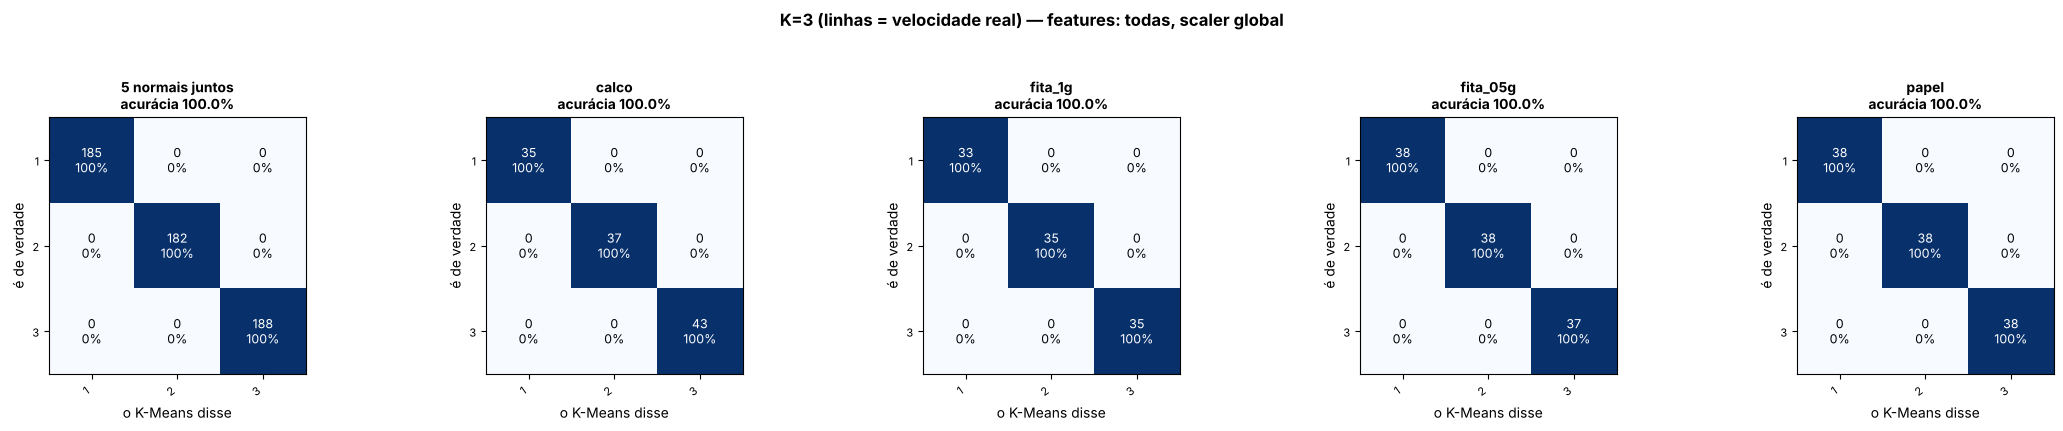

Erros do K=3 com todas as features, por bloco:


,,,erros,janelas
janelas usadas,bloco,velocidade,,


In [11]:
classes_velocidade = list(velocidades)
selecoes_k3 = {"5 normais juntos": gabarito["normal"].to_numpy()}
selecoes_k3.update({a: (gabarito["bloco"] == a).to_numpy() for a in ANOMALIAS})

tabelas_k3, resultados_k3 = {}, {}
for nome, selecao in selecoes_k3.items():
    tabelas_k3[nome], resultados_k3[nome] = comparar_conjuntos(features, gabarito, selecao, len(velocidades), "velocidade", classes_velocidade)
display(pd.concat({n: t[["acurácia (%)", "ARI"]] for n, t in tabelas_k3.items()}, names=["janelas usadas", "features"])
        ["acurácia (%)"].unstack().round(1))

fig, axs = plt.subplots(1, len(selecoes_k3), figsize=(4.4 * len(selecoes_k3), 4.2), squeeze=False)
for ax, nome in zip(axs[0], selecoes_k3):
    r = resultados_k3[nome][CONJUNTO_PRINCIPAL]
    plotar_matriz_de_confusao(r["reais"], r["previstos"], classes_velocidade, f"{nome}\nacurácia {r['metricas']['acurácia (%)']:.1f}%", ax=ax)
fig.suptitle(f"K=3 (linhas = velocidade real) — features: {CONJUNTO_PRINCIPAL}, scaler global", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

print("Erros do K=3 com todas as features, por bloco:")
display(pd.concat({n: erros_por_bloco(r[CONJUNTO_PRINCIPAL]) for n, r in resultados_k3.items()}, names=["janelas usadas"]))

### Conclusões do Passo 5

* **As velocidades aparecem sozinhas:** com todas as features, o K=3 acerta **100%** nos 5 normais juntos e em cada uma das 4 anomalias, sem nenhum erro. Com FFT também é 100%, e com rotação de 99,5% a 100%.
* **Só as features de tempo erram um pouco:** 90,8% nos normais e 88,6% no papel.
* **Diferença para a coleta anterior:** lá o K=3 com todas as features errou o começo do normal V2 (motor frio) e só a rotação dava 99%. Aqui o motor não começa frio, e qualquer conjunto (menos tempo) acha a velocidade.
* **Para a arquitetura "um modelo chama o outro":** descobrir a velocidade sem rótulo continua fácil. A rotação (`f1x_hz`) segue sendo a escolha mais segura para essa etapa, porque também funcionou com o motor frio da outra sessão.

## Passo 6 — K=5 só nos normais: o K-Means separa os lotes?

**O que buscamos:** em cada velocidade, pegamos **só os 5 lotes de normal** e pedimos 5 grupos. **Não há falha nenhuma aqui.** Se o K-Means separar os lotes, ele está enxergando o **momento da sessão** (aquecimento entre lotes), e qualquer separação de uma anomalia precisa ser maior do que isso para valer.

**Scaler:** local "b" (os normais da velocidade), que aqui é o mesmo que um scaler ajustado em todas as janelas do experimento.

**Como ler:** ARI perto de 0 = os lotes são indistinguíveis sem rótulo (bom: o normal é estável). ARI alto = cada lote tem a sua "cara", e o K-Means acha isso sozinho.

Vel 1                         Vel 2                         Vel 3      
                 acurácia balanceada (%)   ARI acurácia balanceada (%)   ARI acurácia balanceada (%)   ARI
tempo                              30.98  0.03                   56.48  0.36                   38.74  0.09
FFT                                56.05  0.39                   53.47  0.33                   31.71  0.04
rotação                            44.32  0.23                   50.62  0.28                   30.82  0.04
todas                              51.71  0.32                   51.92  0.29                   36.16  0.08
todas sem f1x_hz                   51.17  0.32                   51.36  0.29                   37.94  0.08

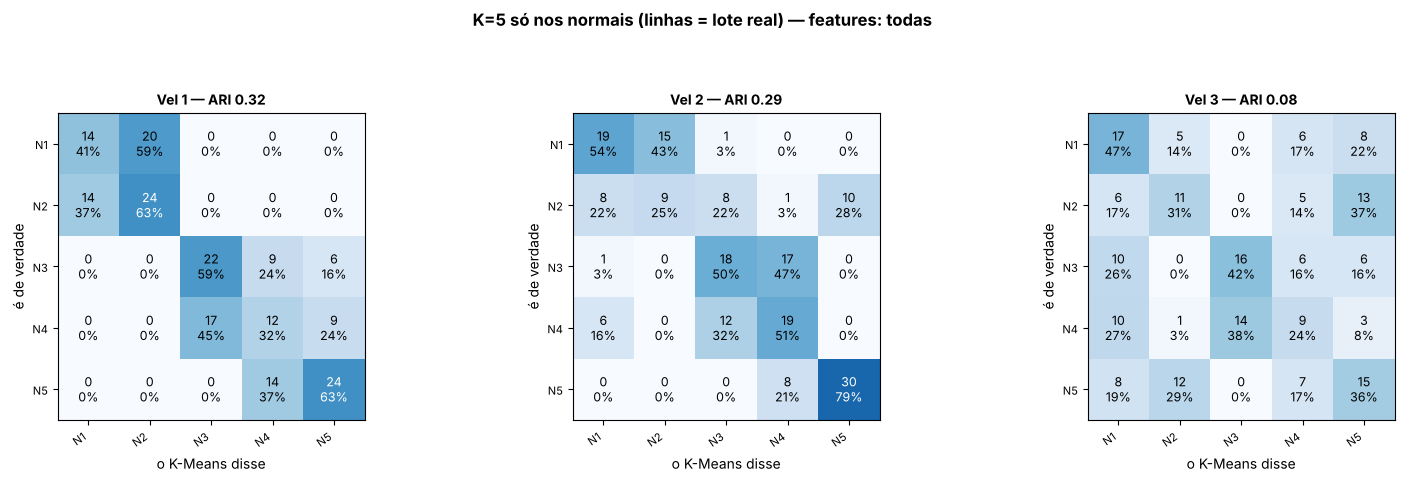

In [12]:
tabelas_lotes, resultados_lotes = {}, {}
for velocidade in velocidades:
    selecao = (gabarito["normal"] & (gabarito["velocidade"] == velocidade)).to_numpy()
    tabelas_lotes[velocidade], resultados_lotes[velocidade] = comparar_conjuntos(
        features, gabarito, selecao, len(BLOCOS_NORMAIS), "bloco", BLOCOS_NORMAIS)
display(pd.concat({f"Vel {v}": t[["acurácia balanceada (%)", "ARI"]] for v, t in tabelas_lotes.items()}, axis=1).round(2))

fig, axs = plt.subplots(1, len(velocidades), figsize=(5.2 * len(velocidades), 4.8), squeeze=False)
for ax, velocidade in zip(axs[0], velocidades):
    r = resultados_lotes[velocidade][CONJUNTO_PRINCIPAL]
    plotar_matriz_de_confusao(r["reais"], r["previstos"], BLOCOS_NORMAIS, f"Vel {velocidade} — ARI {r['metricas']['ARI']:.2f}", ax=ax)
fig.suptitle(f"K=5 só nos normais (linhas = lote real) — features: {CONJUNTO_PRINCIPAL}", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

### Conclusões do Passo 6

* **Os lotes de normal se separam em parte nas Vel 1 e 2 e quase nada na Vel 3:** ARI de **0,32**, **0,29** e **0,08** (todas as features).
* **Vel 1:** o K=5 divide os normais em **começo da sessão (N1 e N2)** e **fim (N3, N4 e N5)**, sem nenhuma janela cruzando de um lado para o outro; dentro de cada lado os lotes se misturam. É o aquecimento entre os lotes (Notebook 02: rotação de 13,2 para 14,0 Hz).
* **Vel 2:** o N5 é o lote mais diferente (79% num grupo só); N1 e N2 ficam juntos.
* **Vel 3:** os lotes ficam misturados, coerente com o Notebook 02 (dois normais quaisquer diferem em no máximo 4 features).
* **Só com as features de tempo, os lotes da Vel 1 não se separam (ARI 0,03):** a diferença entre eles está nas FFT e na rotação, não na intensidade.
* **Consequência:** nas Vel 1 e 2, o K-Means "enxerga" o momento da sessão. Uma anomalia gravada no começo da sessão (o calço, entre N1 e N2) pode ser agrupada com os lotes do começo por esse motivo, e não pela falha.

## Passo 7 — K=2 em cada velocidade: normal × cada anomalia

**O que buscamos:** o teste de detecção sem rótulo. Em cada velocidade, juntamos as janelas de **uma anomalia** com as de uma **referência normal** e pedimos 2 grupos. Duas referências, como no Notebook 02:

* **5 normais juntos:** a anomalia contra tudo o que o normal fez na sessão.
* **Vizinhos:** a anomalia contra os dois lotes gravados logo antes e logo depois dela.

O **scaler local "b"** é ajustado nos 5 lotes de normal da velocidade nos dois casos, para que a régua seja a mesma.

**O experimento binário genérico:** a mesma função serve para as anomalias (Passo 7) e para os placebos (Passo 8). Ela recebe o **bloco testado**, os **blocos de referência** e os **blocos usados no ajuste do scaler**, e devolve recall do bloco testado, falso alarme, acurácia balanceada e ARI.

In [13]:
def encontrar_vizinhos(ordem_blocos, blocos_normais):
    """Para cada bloco (anomalia ou normal), os normais logo antes e logo depois dele na sessão."""
    vizinhos = {}
    for i, bloco in enumerate(ordem_blocos):
        antes = [b for b in ordem_blocos[:i] if b in blocos_normais][-1:]
        depois = [b for b in ordem_blocos[i + 1:] if b in blocos_normais][:1]
        vizinhos[bloco] = antes + depois
    return vizinhos


def experimento_binario(features, gabarito, velocidade, bloco_testado, blocos_referencia, blocos_ajuste, colunas):
    """K=2 entre um bloco testado e blocos de referência, numa velocidade, com scaler ajustado em blocos_ajuste."""
    na_velocidade = (gabarito["velocidade"] == velocidade).to_numpy()
    usados_no_kmeans = [bloco_testado] + list(blocos_referencia)
    universo = na_velocidade & gabarito["bloco"].isin(set(usados_no_kmeans) | set(blocos_ajuste)).to_numpy()
    matriz, rotulos_universo = aplicar_log(features.loc[universo], colunas), gabarito.loc[universo]
    scaler = StandardScaler().fit(matriz[rotulos_universo["bloco"].isin(blocos_ajuste).to_numpy()])   # ajustado só em blocos_ajuste
    usados = rotulos_universo["bloco"].isin(usados_no_kmeans).to_numpy()
    padronizada = pd.DataFrame(scaler.transform(matriz[usados]), index=matriz.index[usados], columns=matriz.columns)
    rotulos = rotulos_universo[usados]
    reais = np.where(rotulos["bloco"] == bloco_testado, "testado", "referência")
    clusters = rodar_kmeans(padronizada, 2)
    metricas, previstos = calcular_metricas(reais, clusters, ["referência", "testado"])
    resumo = {"recall do testado (%)": metricas["recall testado (%)"],
              "falso alarme (%)": 100 - metricas["recall referência (%)"],
              "acurácia balanceada (%)": metricas["acurácia balanceada (%)"], "ARI": metricas["ARI"]}
    return resumo, {"padronizada": padronizada, "clusters": clusters, "previstos": previstos, "reais": reais, "rotulos": rotulos}


def rodar_casos_binarios(features, gabarito, casos, conjuntos=CONJUNTOS):
    """Roda o experimento binário para uma lista de casos (dicionários) e todos os conjuntos de features."""
    linhas, detalhes = [], {}
    for caso in casos:
        for nome, colunas in conjuntos.items():
            resumo, detalhe = experimento_binario(features, gabarito, caso["velocidade"], caso["testado"],
                                                  caso["referencia"], caso["ajuste"], colunas)
            linhas.append({**{k: caso[k] for k in ("tipo", "testado", "nome_referencia", "velocidade")}, "features": nome, **resumo})
            detalhes[(caso["tipo"], caso["testado"], caso["nome_referencia"], caso["velocidade"], nome)] = detalhe
    return pd.DataFrame(linhas), detalhes

In [14]:
vizinhos = encontrar_vizinhos(ORDEM_BLOCOS, BLOCOS_NORMAIS)
casos_anomalias = []
for anomalia in ANOMALIAS:
    for velocidade in velocidades:
        casos_anomalias.append({"tipo": "anomalia", "testado": anomalia, "velocidade": velocidade, "nome_referencia": "5 normais",
                                "referencia": BLOCOS_NORMAIS, "ajuste": BLOCOS_NORMAIS})
        casos_anomalias.append({"tipo": "anomalia", "testado": anomalia, "velocidade": velocidade,
                                "nome_referencia": "vizinhos (" + " e ".join(vizinhos[anomalia]) + ")",
                                "referencia": vizinhos[anomalia], "ajuste": BLOCOS_NORMAIS})
tabela_anomalias, detalhes_anomalias = rodar_casos_binarios(features, gabarito, casos_anomalias)

for metrica in ("acurácia balanceada (%)", "recall do testado (%)", "falso alarme (%)"):
    print(f"{metrica} — features: {CONJUNTO_PRINCIPAL}")
    parte = tabela_anomalias[tabela_anomalias["features"] == CONJUNTO_PRINCIPAL]
    display(parte.pivot_table(index=["testado", "nome_referencia"], columns="velocidade", values=metrica, sort=False).round(1))

acurácia balanceada (%) — features: todas


velocidade                       1      2      3
testado  nome_referencia                        
calco    5 normais            81.9   72.0   93.0
         vizinhos (N1 e N2)  100.0   70.8   86.0
fita_1g  5 normais           100.0  100.0  100.0
         vizinhos (N2 e N3)  100.0  100.0  100.0
fita_05g 5 normais           100.0  100.0  100.0
         vizinhos (N3 e N4)  100.0  100.0  100.0
papel    5 normais           100.0  100.0  100.0
         vizinhos (N4 e N5)  100.0  100.0  100.0

recall do testado (%) — features: todas


velocidade                       1      2      3
testado  nome_referencia                        
calco    5 normais           100.0   94.6   86.0
         vizinhos (N1 e N2)  100.0   81.1   72.1
fita_1g  5 normais           100.0  100.0  100.0
         vizinhos (N2 e N3)  100.0  100.0  100.0
fita_05g 5 normais           100.0  100.0  100.0
         vizinhos (N3 e N4)  100.0  100.0  100.0
papel    5 normais           100.0  100.0  100.0
         vizinhos (N4 e N5)  100.0  100.0  100.0

falso alarme (%) — features: todas


velocidade                      1     2    3
testado  nome_referencia                    
calco    5 normais           36.2  50.5  0.0
         vizinhos (N1 e N2)   0.0  39.4  0.0
fita_1g  5 normais            0.0   0.0  0.0
         vizinhos (N2 e N3)   0.0   0.0  0.0
fita_05g 5 normais            0.0   0.0  0.0
         vizinhos (N3 e N4)   0.0   0.0  0.0
papel    5 normais            0.0   0.0  0.0
         vizinhos (N4 e N5)   0.0   0.0  0.0

In [15]:
def plotar_matrizes_binarias(detalhes, anomalias, velocidades, nome_referencia, conjunto=CONJUNTO_PRINCIPAL, vizinhos=None):
    """Grade (anomalia x velocidade) de matrizes de confusão do K=2."""
    fig, axs = plt.subplots(len(anomalias), len(velocidades), figsize=(3.6 * len(velocidades), 3.1 * len(anomalias)), squeeze=False)
    for i, anomalia in enumerate(anomalias):
        nome = nome_referencia if vizinhos is None else "vizinhos (" + " e ".join(vizinhos[anomalia]) + ")"
        for j, velocidade in enumerate(velocidades):
            d = detalhes[("anomalia", anomalia, nome, velocidade, conjunto)]
            reais = np.where(d["reais"] == "testado", anomalia, NOME_NORMAL)
            previstos = np.where(d["previstos"] == "testado", anomalia, NOME_NORMAL)
            plotar_matriz_de_confusao(reais, previstos, [NOME_NORMAL, anomalia], f"{anomalia} — Vel {velocidade}", ax=axs[i, j])
    fig.suptitle(f"K=2 normal × anomalia, referência: {nome_referencia} — features: {conjunto}, scaler local (b)", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

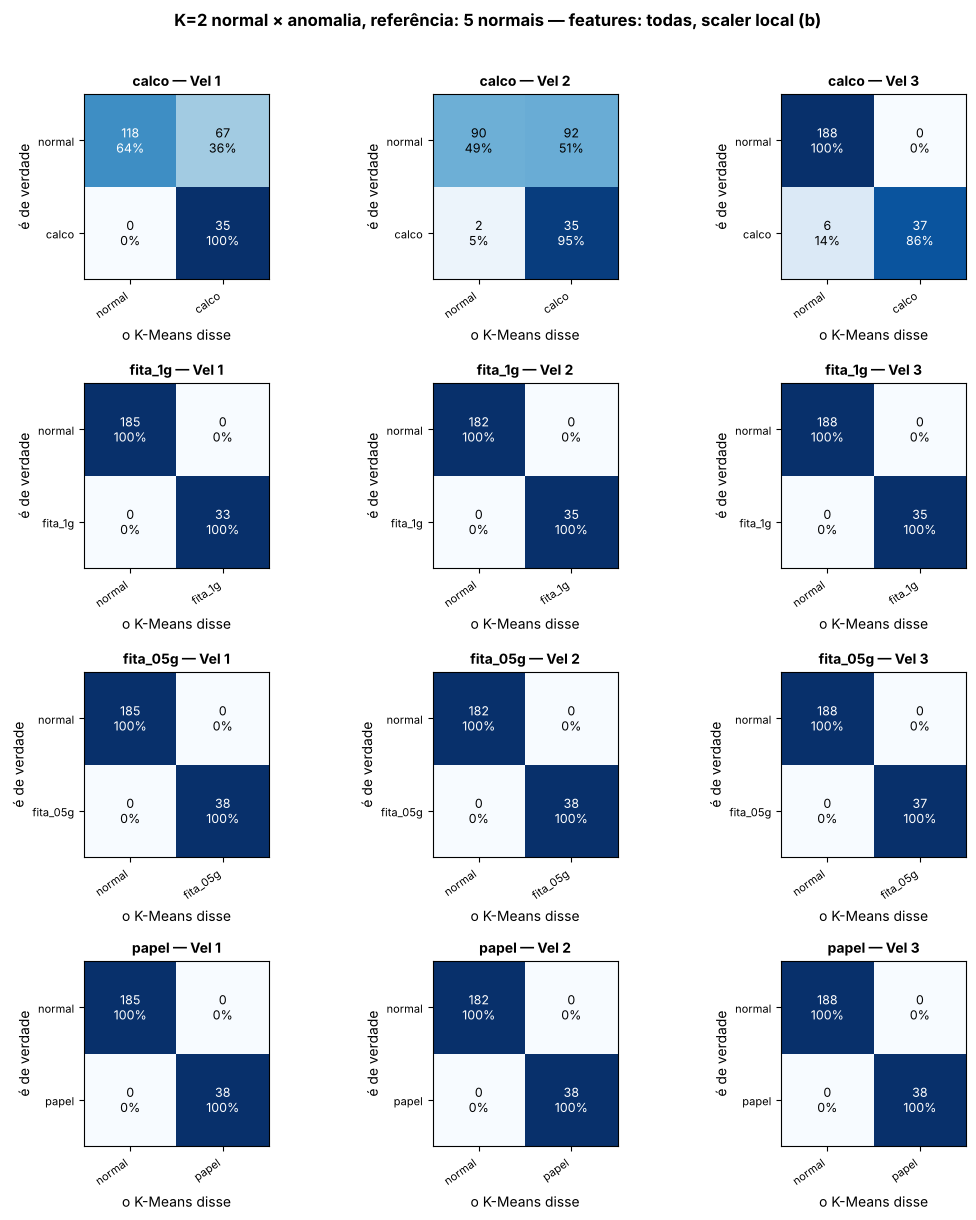

In [16]:
plotar_matrizes_binarias(detalhes_anomalias, ANOMALIAS, velocidades, "5 normais")

### Conclusões do Passo 7

* **Fita 1 g, fita 0,5 g e papel: 100%** de acurácia balanceada nas três velocidades, contra os 5 normais e contra os vizinhos, com **0% de falso alarme**. Inclusive a fita 0,5 g na Vel 1, o caso mais fraco das três no Notebook 02.
* **Calço:**

| | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| contra os 5 normais: recall / falso alarme | 100% / 36% | 95% / 51% | 86% / **0%** |
| contra os vizinhos: recall / falso alarme | **100% / 0%** | 81% / 39% | 72% / **0%** |

* **Vel 3:** o K=2 isola o calço sem acusar nenhuma janela normal.
* **Vel 1:** contra os vizinhos, o calço fica sozinho num grupo (100% e 0%). Contra os 5 normais, o falso alarme de 36% tem uma explicação clara: **o K=2 separou começo × fim da sessão** (N1, calço e quase todo o N2 num grupo; N3, N4 e N5 no outro). O calço entrou junto com os lotes do começo.
* **Vel 2:** os falsos alarmes de 39% a 51% vêm do mesmo tipo de divisão (N1 e o calço de um lado, N5 do outro, N2 a N4 divididos). Aqui o K-Means não acha o calço.

## Passo 8 — O teste do calço: ele se separa mais do que um lote normal?

**O que buscamos:** a resposta direta à pergunta "o K-Means enxerga o calço?". O Passo 7 diz **quanto** o K=2 separa o calço do normal. Este passo diz se isso é **mais do que o K=2 separaria sem falha nenhuma**.

**O placebo:** repetimos exatamente o mesmo experimento binário, mas com um **lote normal no lugar do calço**:

| Placebo | Lote testado | Referência | Equivale a |
| --- | --- | --- | --- |
| **vizinhos** | N2, N3 e N4 | os lotes normais de antes e de depois (por exemplo, N3 contra N2 e N4) | calço contra N1 e N2 |
| **outros 4** | N1 a N5 | os outros 4 lotes | calço contra os 5 normais |

Em todos os placebos, **o lote testado fica fora do ajuste do scaler** (ele é tratado como uma gravação nova, como o calço).

**Como ler a figura:** um painel por velocidade; no eixo horizontal, os conjuntos de features. Os **pontos cinza** são os placebos e o **losango vermelho** é o calço. **O calço só "aparece" de verdade quando o losango fica claramente acima de todos os pontos cinza.** Se ele ficar no meio deles, o K-Means separa o calço tanto quanto separa um lote normal de outro, ou seja, não dá para dizer que ele enxerga a falha.

**Limitação (a mesma do Notebook 02):** os vizinhos do placebo estão mais distantes no tempo (N2 e N4 têm 4 blocos entre si; N1 e N2, só 2). Vizinhos mais distantes diferem mais entre si, o que deixa o placebo um pouco **mais fácil de separar**, não mais difícil. A régua fica, se tanto, exigente demais.

In [17]:
def montar_casos_placebo(velocidades, blocos_normais, vizinhos):
    """Casos de placebo: cada lote normal do meio contra os seus vizinhos normais, e cada lote contra os outros 4."""
    casos = []
    for velocidade in velocidades:
        for i, lote in enumerate(blocos_normais):
            outros = [b for b in blocos_normais if b != lote]
            casos.append({"tipo": "placebo", "testado": lote, "velocidade": velocidade, "nome_referencia": "outros 4",
                          "referencia": outros, "ajuste": outros})
            if 0 < i < len(blocos_normais) - 1:
                viz = [blocos_normais[i - 1], blocos_normais[i + 1]]
                casos.append({"tipo": "placebo", "testado": lote, "velocidade": velocidade,
                              "nome_referencia": "vizinhos (" + " e ".join(viz) + ")", "referencia": viz, "ajuste": outros})
    return casos


def comparar_com_placebo(tabela_anomalias, tabela_placebo, anomalia, metrica="acurácia balanceada (%)"):
    """Por velocidade e conjunto: a métrica da anomalia (vizinhos e 5 normais) e o maior/mediano placebo equivalente."""
    linhas = []
    for (velocidade, conjunto), parte in tabela_placebo.groupby(["velocidade", "features"]):
        viz = parte[parte["nome_referencia"].str.startswith("vizinhos")][metrica]
        outros = parte[parte["nome_referencia"] == "outros 4"][metrica]
        anom = tabela_anomalias[(tabela_anomalias["testado"] == anomalia) & (tabela_anomalias["velocidade"] == velocidade)
                                & (tabela_anomalias["features"] == conjunto)]
        linhas.append({
            "velocidade": velocidade, "features": conjunto,
            f"{anomalia} × vizinhos": anom[anom["nome_referencia"].str.startswith("vizinhos")][metrica].iloc[0],
            "placebo vizinhos (maior)": viz.max(), "placebo vizinhos (mediana)": viz.median(),
            f"{anomalia} × 5 normais": anom[anom["nome_referencia"] == "5 normais"][metrica].iloc[0],
            "placebo outros 4 (maior)": outros.max(), "placebo outros 4 (mediana)": outros.median(),
        })
    tabela = pd.DataFrame(linhas)
    tabela["features"] = pd.Categorical(tabela["features"], list(CONJUNTOS))
    return tabela.sort_values(["velocidade", "features"]).set_index(["velocidade", "features"])


def plotar_teste_contra_placebo(tabela_anomalias, tabela_placebo, anomalia, nome_referencia_placebo, prefixo_anomalia,
                                metrica="acurácia balanceada (%)"):
    """Um painel por velocidade: a métrica de cada placebo (pontos cinza) e da anomalia (losango vermelho), por conjunto."""
    conjuntos = list(CONJUNTOS)
    fig, axs = plt.subplots(1, len(velocidades), figsize=(5.6 * len(velocidades), 4.4), sharey=True, squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        for x, conjunto in enumerate(conjuntos):
            p = tabela_placebo[(tabela_placebo["velocidade"] == velocidade) & (tabela_placebo["features"] == conjunto)
                               & tabela_placebo["nome_referencia"].str.startswith(nome_referencia_placebo)]
            ax.scatter(np.full(len(p), x) + np.linspace(-0.12, 0.12, len(p)), p[metrica], color=COR_PLACEBO, s=28, alpha=0.8)
            a = tabela_anomalias[(tabela_anomalias["testado"] == anomalia) & (tabela_anomalias["velocidade"] == velocidade)
                                 & (tabela_anomalias["features"] == conjunto) & tabela_anomalias["nome_referencia"].str.startswith(prefixo_anomalia)]
            ax.scatter([x], a[metrica], color=COR_ANOMALIA, marker="D", s=80, zorder=3)
        ax.axhline(50, color="black", linewidth=0.8, linestyle=":")
        ax.set_xticks(range(len(conjuntos)))
        ax.set_xticklabels(conjuntos, rotation=30, ha="right")
        ax.set_ylim(40, 102)
        ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
    axs[0, 0].set_ylabel(metrica)
    fig.legend(handles=[Line2D([], [], color=COR_PLACEBO, marker="o", linestyle="", label=f"placebo: lote normal × {nome_referencia_placebo}"),
                        Line2D([], [], color=COR_ANOMALIA, marker="D", linestyle="", label=f"{anomalia} × {prefixo_anomalia}"),
                        Line2D([], [], color="black", linestyle=":", label="acaso (50%)")],
               loc="upper center", ncol=3, fontsize=10, bbox_to_anchor=(0.5, 0.97))
    fig.suptitle(f"K=2: {anomalia} contra o placebo — referência: {prefixo_anomalia}", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

Acurácia balanceada (%) do K=2: calco e os placebos equivalentes


calco × vizinhos  placebo vizinhos (maior)  placebo vizinhos (mediana)  calco × 5 normais  placebo outros 4 (maior)  placebo outros 4 (mediana)
velocidade features                                                                                                                                                         
1          tempo                         47.7                      51.5                        49.8               50.7                      53.0                        51.7
           FFT                          100.0                      75.7                        75.4              100.0                      84.0                        81.8
           rotação                       98.6                      70.1                        68.0               81.9                      86.1                        76.2
           todas                        100.0                      76.1                        75.0               81.9                      86.4                        80.6
           todas sem f1x_hz             100.0                      76.1                        75.0               81.6                      87.1                        83.3
2          tempo                         68.8                      66.1                        64.1               34.9                      69.4                        62.6
           FFT                           70.2                      62.8                        55.8               73.4                      84.4                        60.1
           rotação                       79.0                      66.9                        65.5               50.8                      72.8                        70.0
           todas                         70.8                      62.8                        60.6               72.0                      84.0                        60.4
           todas sem f1x_hz              70.8                      62.8                        60.6               72.3                      84.0                        60.4
3          tempo                         95.3                      67.8                        65.5               95.3                      73.9                        35.9
           FFT                           81.4                      61.9                        61.7               83.7                      67.4                        58.1
           rotação                      100.0                      60.6                        59.6              100.0                      58.4                        52.7
           todas                         86.0                      64.4                        61.9               93.0                      70.4                        61.3
           todas sem f1x_hz              86.0                      63.2                        61.9               93.0                      70.4                        61.3

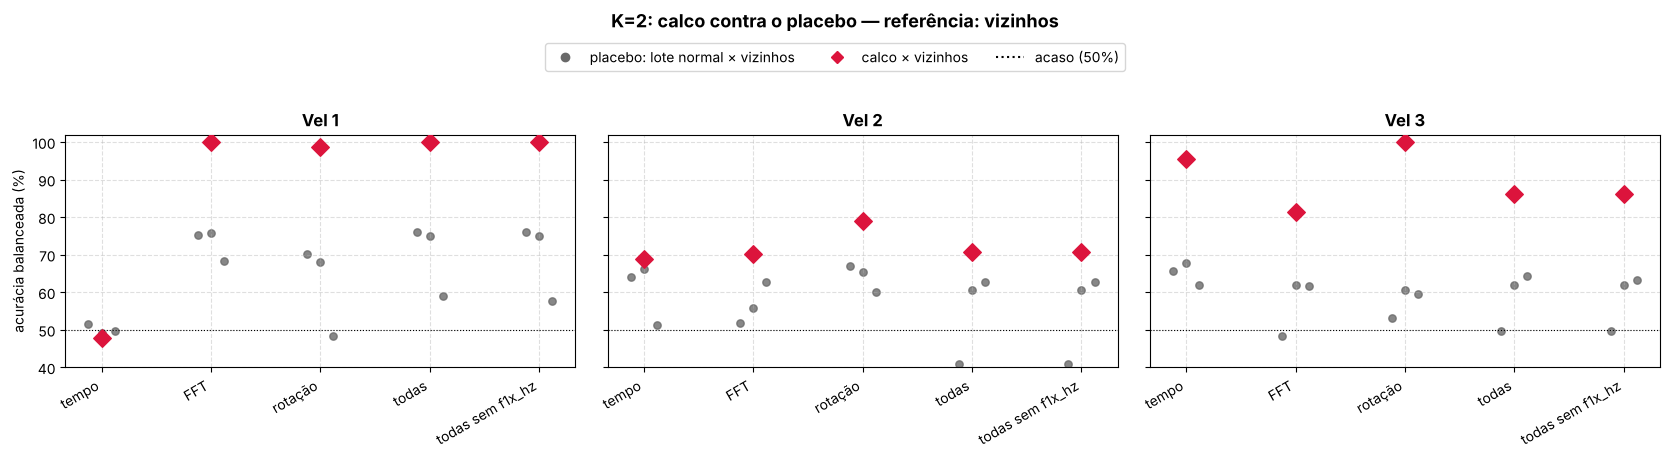

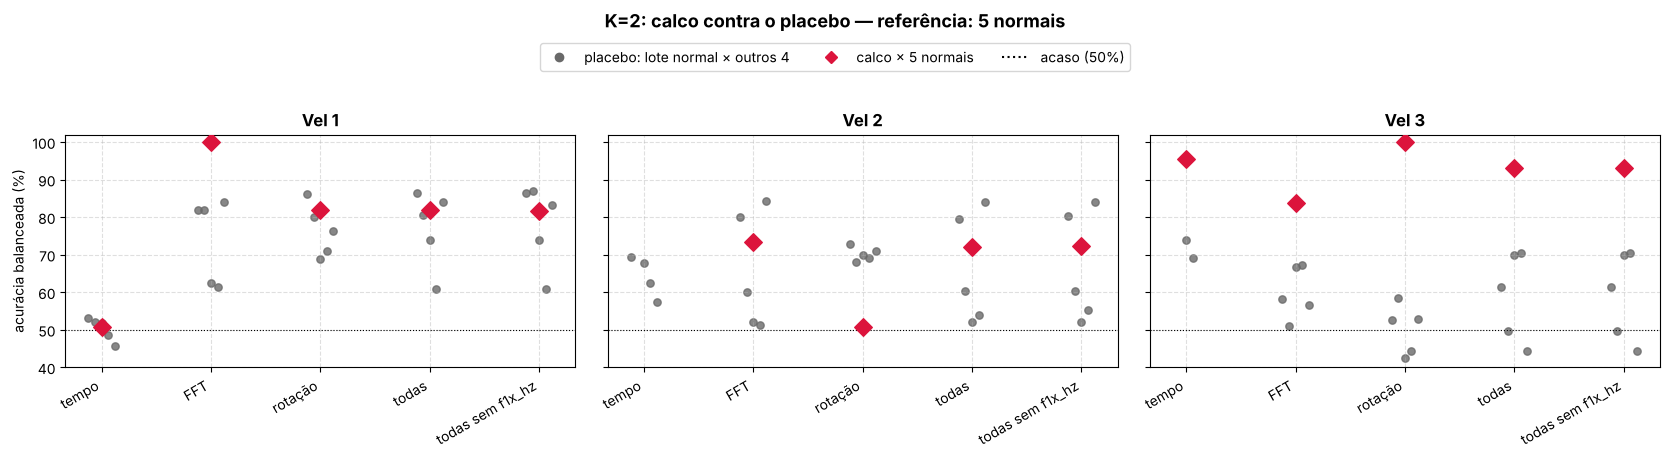

In [18]:
tabela_placebo, detalhes_placebo = rodar_casos_binarios(features, gabarito, montar_casos_placebo(velocidades, BLOCOS_NORMAIS, vizinhos))
comparacao_foco = comparar_com_placebo(tabela_anomalias, tabela_placebo, CONDICAO_FOCO)
print(f"Acurácia balanceada (%) do K=2: {CONDICAO_FOCO} e os placebos equivalentes")
display(comparacao_foco.round(1))
plotar_teste_contra_placebo(tabela_anomalias, tabela_placebo, CONDICAO_FOCO, "vizinhos", "vizinhos")
plotar_teste_contra_placebo(tabela_anomalias, tabela_placebo, CONDICAO_FOCO, "outros 4", "5 normais")

### Conclusões do Passo 8

**Acurácia balanceada do K=2 (todas as features):**

| | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| calço × vizinhos | **100** | 70,8 | **86,0** |
| maior placebo × vizinhos | 76,1 | 62,8 | 64,4 |
| calço × 5 normais | 81,9 | 72,0 | **93,0** |
| maior placebo × outros 4 | 86,4 | 84,0 | 70,4 |

* **Vel 3: o K-Means enxerga o calço.** Ele fica de 21 a 23 pontos acima do pior caso do placebo nas duas referências, em todos os conjuntos de features. As maiores folgas vêm das features de **tempo** (95,3 contra 67,8) e de **rotação/harmônicas** (100 contra 60,6), coerente com o Notebook 02 (vibração maior em Y e Z, 1X do eixo Z 3 vezes maior).
* **Vel 1: enxerga, mas a variação entre lotes compete.**
  * Contra os vizinhos, o calço separa 100%, 24 pontos acima do maior placebo, **também sem `f1x_hz`** (100 contra 76,1). A diferença não é só a rotação mais lenta.
  * Só com **FFT**, ele separa 100% também contra os 5 normais (placebo máximo de 84,0).
  * Com todas as features contra os 5 normais (81,9), ele fica **abaixo** do placebo N1 × outros 4 (86,4): a divisão começo × fim da sessão é mais "barata" para o K-Means do que isolar 35 janelas de calço.
  * **Só com features de tempo o calço não aparece** (47,7, no nível do acaso), como já tinha mostrado o Notebook 01.
* **Vel 2: não enxerga.** O calço fica só 8 pontos acima do placebo dos vizinhos (70,8 contra 62,8) e abaixo do placebo contra os 5 normais (72,0 contra 84,0). É a mesma velocidade em que o Notebook 02 achou o calço mais fraco (18 features contra 12 do placebo).
* **Os placebos mais altos são as pontas da sessão:** N1 e N5 contra os outros 4 chegam a 84–86% nas Vel 1 e 2. **Um lote normal de uma ponta da sessão já é separável sem falha nenhuma**, e é essa a régua contra a qual o calço precisa se destacar.

**Resposta à pergunta do notebook:** o K-Means enxerga o calço **com clareza na Vel 3**, **na Vel 1 quando o normal de referência é o do mesmo trecho da sessão (ou só com FFT)** e **não na Vel 2**.

### 8.1 — Onde o calço cai no mapa (PCA)

**O que buscamos:** ver com os olhos. Em cada velocidade, projetamos as janelas dos **5 lotes de normal e do calço** em 2 dimensões (PCA), depois do log e do scaler local "b" (ajustado nos 5 normais), com todas as features. Cada lote tem uma cor (tons de azul, do N1 claro ao N5 escuro) e o calço é vermelho.

* **Calço formando uma nuvem própria, longe dos azuis:** o calço tem uma "cara" que nenhum lote normal tem.
* **Calço no meio dos azuis:** não se distingue.
* **Lotes azuis formando nuvens separadas entre si:** o normal muda de lote para lote (o que o Passo 6 mediu).

**Cuidado:** o PCA mostra só as 2 direções de maior variação. Uma separação pode existir em outras direções e não aparecer aqui (o K-Means usa todas).

In [19]:
def plotar_pca_por_bloco(features, gabarito, blocos, velocidades, colunas, destaque):
    """Um painel por velocidade: PCA 2D (log + scaler ajustado nos normais), cor por bloco, com o destaque em vermelho."""
    cores_normais = plt.cm.Blues(np.linspace(0.35, 0.95, len(BLOCOS_NORMAIS)))
    cores = {b: cores_normais[i] for i, b in enumerate(BLOCOS_NORMAIS)}
    fig, axs = plt.subplots(1, len(velocidades), figsize=(6 * len(velocidades), 5.2), squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        selecao = ((gabarito["velocidade"] == velocidade) & gabarito["bloco"].isin(blocos)).to_numpy()
        rotulos = gabarito.loc[selecao]
        padronizada = padronizar(aplicar_log(features.loc[selecao], colunas), janelas_de_ajuste=rotulos["normal"].to_numpy())
        pca = PCA(n_components=2, random_state=SEMENTE)
        pontos = pca.fit_transform(padronizada.to_numpy())
        for bloco in blocos:
            sel = (rotulos["bloco"] == bloco).to_numpy()
            ax.scatter(pontos[sel, 0], pontos[sel, 1], s=28 if bloco == destaque else 16,
                       color=COR_ANOMALIA if bloco == destaque else cores[bloco],
                       marker="D" if bloco == destaque else "o", alpha=0.85, label=bloco,
                       edgecolor="black" if bloco == destaque else "none", linewidth=0.4)
        explicada = 100 * pca.explained_variance_ratio_
        ax.set_xlabel(f"PC1 ({explicada[0]:.0f}% da variação)")
        ax.set_ylabel(f"PC2 ({explicada[1]:.0f}% da variação)")
        ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
    handles, labels = axs[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(blocos), fontsize=10, bbox_to_anchor=(0.5, 0.97))
    fig.suptitle(f"PCA dos 5 lotes de normal e de {destaque} (todas as features, scaler ajustado nos normais)", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

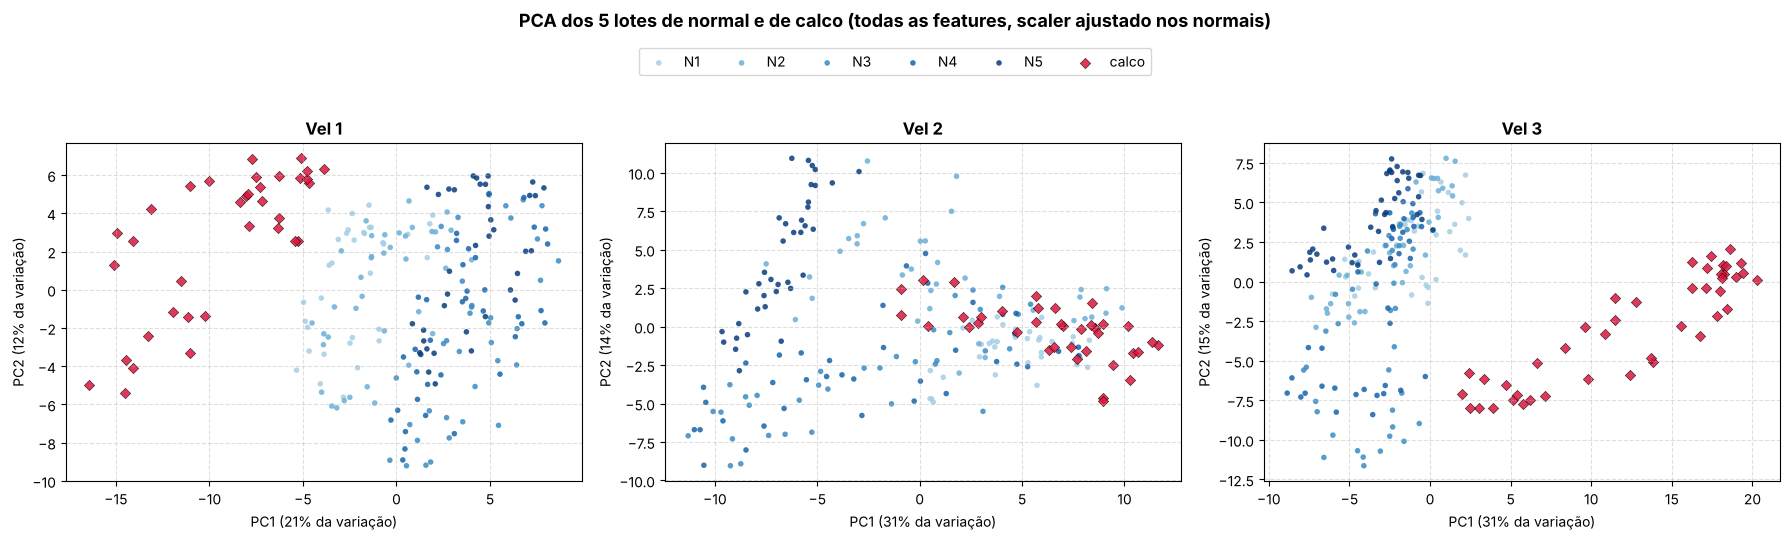

In [20]:
plotar_pca_por_bloco(features, gabarito, BLOCOS_NORMAIS + [CONDICAO_FOCO], velocidades, COLUNAS_TODAS, CONDICAO_FOCO)

### Conclusões do Passo 8.1

* **Vel 3:** o calço forma uma **nuvem própria, longe de todos os lotes** (à direita no PC1), e os 5 lotes de normal ficam misturados entre si à esquerda. É a imagem do "K-Means enxerga o calço".
* **Vel 1:** o calço também fica **separado** (à esquerda no PC1), mas os lotes normais se espalham num gradiente, do N1 (claro) perto do calço ao N5 (escuro) do outro lado. O calço fica do lado dos lotes do começo da sessão, o que explica por que o K=2 o juntou com N1 e N2 quando tinha de dividir tudo em só 2 grupos.
* **Vel 2:** o calço fica **no meio** dos lotes N1 e N2; os lotes N3 a N5 se espalham para a esquerda. Não há separação visível.

### 8.2 — As outras anomalias contra o mesmo placebo

**O que buscamos:** a mesma comparação do Passo 8 para as quatro anomalias, numa tabela só, com o conjunto principal e com "todas sem f1x_hz". Serve de régua para o calço: as falhas fortes devem ficar muito acima do placebo.

Para cada anomalia e velocidade: a acurácia balanceada contra os vizinhos e o **maior placebo de vizinhos** da mesma velocidade e conjunto. A coluna **folga** é a diferença (positiva = a anomalia separa mais que o pior caso do placebo).

In [21]:
def folga_sobre_placebo(tabela_anomalias, tabela_placebo, anomalias, conjuntos, metrica="acurácia balanceada (%)"):
    """Para cada anomalia, velocidade e conjunto: a métrica contra os vizinhos, o maior placebo de vizinhos e a folga."""
    linhas = []
    for anomalia in anomalias:
        for velocidade in velocidades:
            for conjunto in conjuntos:
                a = tabela_anomalias[(tabela_anomalias["testado"] == anomalia) & (tabela_anomalias["velocidade"] == velocidade)
                                     & (tabela_anomalias["features"] == conjunto) & tabela_anomalias["nome_referencia"].str.startswith("vizinhos")][metrica].iloc[0]
                p = tabela_placebo[(tabela_placebo["velocidade"] == velocidade) & (tabela_placebo["features"] == conjunto)
                                   & tabela_placebo["nome_referencia"].str.startswith("vizinhos")][metrica].max()
                linhas.append({"anomalia": anomalia, "velocidade": velocidade, "features": conjunto,
                               "anomalia × vizinhos": a, "maior placebo": p, "folga": a - p})
    return pd.DataFrame(linhas).pivot_table(index=["anomalia", "features"], columns="velocidade",
                                            values=["anomalia × vizinhos", "maior placebo", "folga"], sort=False)

In [22]:
display(folga_sobre_placebo(tabela_anomalias, tabela_placebo, ANOMALIAS, [CONJUNTO_PRINCIPAL, "todas sem f1x_hz"]).round(1))

anomalia × vizinhos               maior placebo             folga            
velocidade                                  1      2      3             1     2     3     1     2     3
anomalia features                                                                                      
calco    todas                          100.0   70.8   86.0          76.1  62.8  64.4  23.9   8.0  21.6
         todas sem f1x_hz               100.0   70.8   86.0          76.1  62.8  63.2  23.9   8.0  22.9
fita_1g  todas                          100.0  100.0  100.0          76.1  62.8  64.4  23.9  37.2  35.6
         todas sem f1x_hz               100.0  100.0  100.0          76.1  62.8  63.2  23.9  37.2  36.8
fita_05g todas                          100.0  100.0  100.0          76.1  62.8  64.4  23.9  37.2  35.6
         todas sem f1x_hz               100.0  100.0  100.0          76.1  62.8  63.2  23.9  37.2  36.8
papel    todas                          100.0  100.0  100.0          76.1  62.8  64.4  23.9  37.2  35.6
         todas sem f1x_hz               100.0  100.0  100.0          76.1  62.8  63.2  23.9  37.2  36.8

### Conclusões do Passo 8.2

* **Fitas e papel:** 100% contra os vizinhos nas três velocidades, de 24 a 37 pontos acima do maior placebo, com ou sem `f1x_hz`.
* **Calço:** folga de **24, 8 e 22 pontos** (Vel 1, 2 e 3), igual com ou sem `f1x_hz`. A Vel 2 é a única velocidade em que alguma anomalia fica perto do placebo.
* **Tirar `f1x_hz` não muda nada** no K-Means com todas as features: a rotação é 1 de 109 features e, depois do scaler, pesa pouco na distância. O efeito dela no classificador supervisionado (Notebook 05) pode ser diferente, porque lá o modelo pode escolher dar peso a uma feature só.

## Passo 9 — Todas as condições ao mesmo tempo: K=5 em cada velocidade e K=15

**O que buscamos:** em vez de uma anomalia por vez, juntar tudo e ver se os grupos batem com as condições.

* **K=5 em cada velocidade** (scaler local "b"): normal (os 5 lotes juntos) + as 4 anomalias. É o mais parecido com o uso real: a velocidade é conhecida e queremos saber a condição.
* **K=15 com tudo junto** (scaler global): 3 velocidades × 5 condições, sem informar a velocidade. Na coleta anterior o equivalente (K=12) acertou 79%.

**Cuidado:** o normal tem cerca de 185 janelas por velocidade e cada anomalia, cerca de 37. O K-Means tende a dividir o grupo grande (por exemplo, separar lotes de normal) em vez de achar a anomalia fraca. Por isso a matriz de confusão importa mais que a acurácia.

Vel 1                         Vel 2                         Vel 3      
                 acurácia balanceada (%)   ARI acurácia balanceada (%)   ARI acurácia balanceada (%)   ARI
tempo                              74.40  0.43                   63.96  0.47                   65.53  0.69
FFT                               100.00  1.00                   88.83  0.50                   93.49  0.89
rotação                            71.46  0.58                   80.33  0.53                   97.30  0.99
todas                              92.65  0.56                   88.81  0.50                   97.21  0.95
todas sem f1x_hz                   92.65  0.56                   88.92  0.50                   97.21  0.95

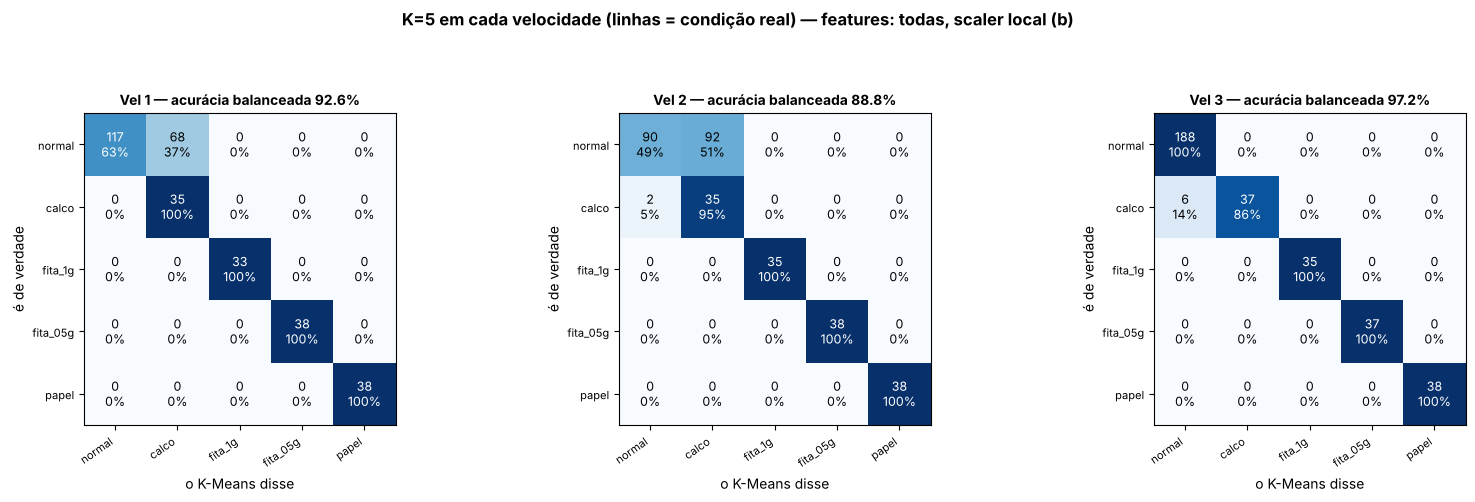

In [23]:
tabelas_k5, resultados_k5 = {}, {}
for velocidade in velocidades:
    selecao = (gabarito["velocidade"] == velocidade).to_numpy()
    tabelas_k5[velocidade], resultados_k5[velocidade] = comparar_conjuntos(
        features, gabarito, selecao, len(ORDEM_CONDICOES), "condicao", ORDEM_CONDICOES,
        grupos_scaler="velocidade", ajuste_scaler=gabarito["normal"].to_numpy())
display(pd.concat({f"Vel {v}": t[["acurácia balanceada (%)", "ARI"]] for v, t in tabelas_k5.items()}, axis=1).round(2))

fig, axs = plt.subplots(1, len(velocidades), figsize=(5.4 * len(velocidades), 5), squeeze=False)
for ax, velocidade in zip(axs[0], velocidades):
    r = resultados_k5[velocidade][CONJUNTO_PRINCIPAL]
    plotar_matriz_de_confusao(r["reais"], r["previstos"], ORDEM_CONDICOES,
                              f"Vel {velocidade} — acurácia balanceada {r['metricas']['acurácia balanceada (%)']:.1f}%", ax=ax)
fig.suptitle(f"K=5 em cada velocidade (linhas = condição real) — features: {CONJUNTO_PRINCIPAL}, scaler local (b)", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

,acurácia (%),acurácia balanceada (%),ARI
tempo,63.5,57.56,0.61
FFT,74.0,82.51,0.67
rotação,61.3,71.42,0.55
todas,78.7,88.80,0.72
todas sem f1x_hz,74.4,82.94,0.66


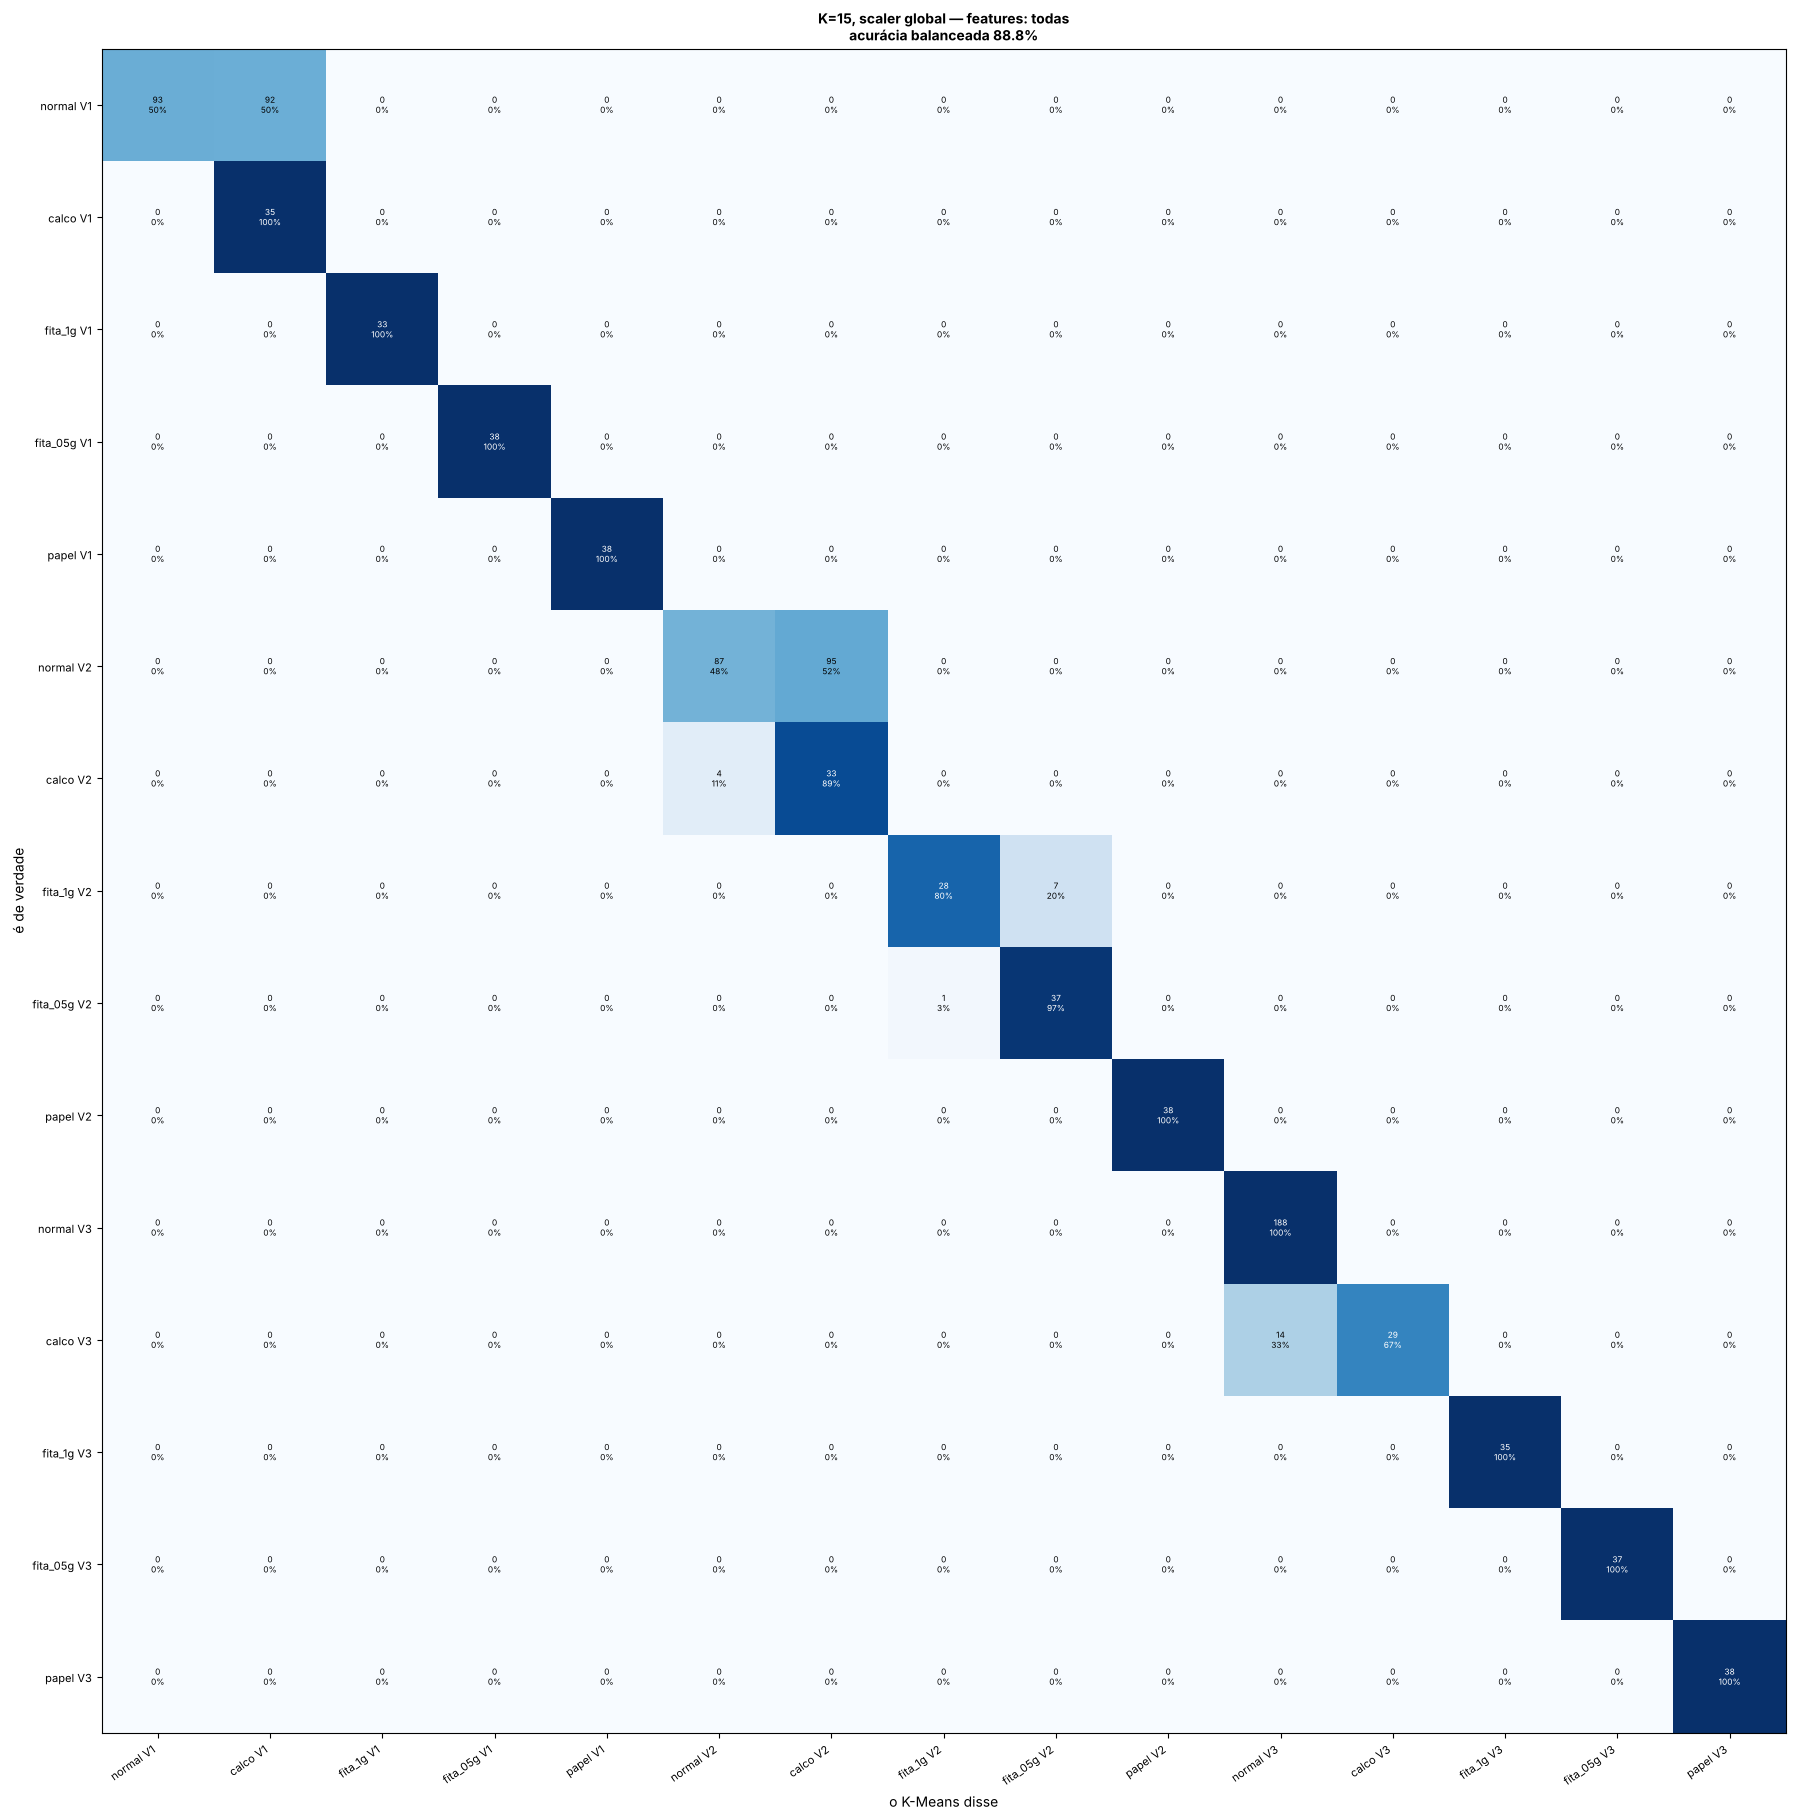

In [24]:
ORDEM_CLASSES = [f"{c} V{v}" for v in velocidades for c in ORDEM_CONDICOES]
tabela_k15, resultados_k15 = comparar_conjuntos(features, gabarito, np.ones(len(features), dtype=bool), len(ORDEM_CLASSES), "classe", ORDEM_CLASSES)
display(tabela_k15[["acurácia (%)", "acurácia balanceada (%)", "ARI"]].round(2))
r = resultados_k15[CONJUNTO_PRINCIPAL]
plotar_matriz_de_confusao(r["reais"], r["previstos"], ORDEM_CLASSES, f"K=15, scaler global — features: {CONJUNTO_PRINCIPAL}\n"
                          f"acurácia balanceada {r['metricas']['acurácia balanceada (%)']:.1f}%")

### Conclusões do Passo 9

**K=5 em cada velocidade (normal + 4 anomalias, scaler local "b"):**
* **Vel 3: 97,2%** de acurácia balanceada. Normal, fita 1 g, fita 0,5 g e papel com 100%; o calço com 86% (6 janelas no grupo do normal).
* **Vel 1: 92,6%**. As 4 anomalias com 100%, mas o normal se divide: 68 janelas (do começo da sessão) caem no grupo do calço. **Só com FFT, a Vel 1 dá 100% com ARI de 1,00**: as cinco condições separadas perfeitamente, calço inclusive.
* **Vel 2: 88,8%**. As 3 falhas fortes com 100%; normal e calço se misturam (metade do normal no grupo do calço).
* **Lição:** quando o K-Means tem um grupo "sobrando", ele prefere dividir o normal (que é grande e espalhado pelos lotes) a isolar uma anomalia fraca. As falhas fortes nunca são afetadas.

**K=15 (tudo junto, scaler global):** 78,7% de acurácia (88,8% balanceada; ARI 0,72) com todas as features, praticamente igual aos 79,1% do K=12 na coleta anterior.

## Resumo e decisões para o Notebook 05 (NOVOS_2.0)

**Respostas diretas:**

1. **O K-Means acha as velocidades?** Sim: 100% com todas as features, nos normais e em cada anomalia.
2. **Os lotes de normal se separam sozinhos?** Em parte, nas Vel 1 e 2 (ARI de cerca de 0,3: começo × fim da sessão); quase nada na Vel 3 (ARI 0,08).
3. **Detecta as falhas fortes?** Fita 1 g, fita 0,5 g e papel: **100%, com 0% de falso alarme**, nas três velocidades e nas duas referências.
4. **Enxerga o calço?**
   * **Vel 3:** sim, com clareza (93% contra os 5 normais, 0% de falso alarme, mais de 20 pontos acima do placebo).
   * **Vel 1:** sim, contra os vizinhos (100%) e só com FFT (100% contra os 5 normais), também sem `f1x_hz`. Com todas as features contra os 5 normais, a divisão começo × fim da sessão vence.
   * **Vel 2:** não (só 8 pontos acima do placebo).

| Decisão / indicação | Por quê |
| --- | --- |
| **Etapa de velocidade com `f1x_hz`** (mantida) | 100% aqui e 100% na outra sessão (Notebook 05 anterior) |
| **Scaler local "b" e log** (mantidos) | As falhas fortes ficam a 100% com eles |
| **Indicação para o calço na regra dos 85%:** Vel 3 provável, Vel 1 possível, Vel 2 improvável | Leitura sem rótulos; a regra é medida no Notebook 05, com modelo supervisionado e validação por blocos |
| **Comparar FFT e todas as features no Notebook 05** | Na Vel 1, só a FFT isolou o calço contra os 5 normais |

**O que este notebook ensina para o Notebook 05:** um modelo pode separar uma anomalia **pela gravação**, e não pela falha. Aqui, um lote normal das pontas da sessão chega a 84–86% de acurácia balanceada no K=2 **sem falha nenhuma**. No Notebook 05, o teste trancado é feito com blocos **dentro das mesmas gravações**, então ele não protege contra esse efeito: o classificador vê o calço no treino e no teste vindo da mesma gravação. A forma de medir isso é a mesma do Passo 8: **rodar o mesmo modelo supervisionado com um lote normal no lugar da anomalia (placebo)**. Se o placebo também passar de 85%, o critério não distingue falha de gravação.

**Perguntas para o grupo:** as mesmas de antes. A ordem real entre as fitas não muda nada aqui (as duas ficam a 100%), mas muda os vizinhos delas.

## O que conferir antes de seguir para o Notebook 05

* [ ] **Passo 5:** as velocidades aparecem sozinhas com todas as features.
* [ ] **Passo 6:** você viu que os lotes de normal das Vel 1 e 2 se dividem em começo × fim da sessão.
* [ ] **Passo 7:** fitas e papel a 100%; o calço com falso alarme alto nas Vel 1 e 2 contra os 5 normais, e a explicação (divisão começo × fim).
* [ ] **Passo 8:** o calço contra o placebo: claro na Vel 3, claro na Vel 1 contra os vizinhos ou só com FFT, ausente na Vel 2.
* [ ] **Resumo:** a proposta de um placebo supervisionado no Notebook 05 está entendida.

**Próximo passo:** Notebook 05, a **classificação supervisionada**, com o teste trancado de blocos de 30 s, a regra do calço a 85%, XGBoost e HistGradientBoosting.